# CineRL: Tabular Q-Learning Movie Recommender

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import time
import json

from pathlib import Path

In [3]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

# Load prepared datasets
train_ratings = pd.read_csv(
    PROCESSED_DIR / "train_ratings.csv"
)

test_ratings = pd.read_csv(
    PROCESSED_DIR / "test_ratings.csv"
)

movies = pd.read_csv(
    PROCESSED_DIR / "movies.csv"
)

print("Data loaded successfully.")

Data loaded successfully.


In [4]:
print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)
print("Movies:", movies.shape)

print("\nTraining columns:", train_ratings.columns.tolist())
print("Testing columns:", test_ratings.columns.tolist())
print("Movie columns:", movies.columns.tolist())

print("\nMissing values in training data:")
print(train_ratings.isnull().sum())

Training ratings: (797758, 4)
Testing ratings: (202451, 4)
Movies: (3883, 3)

Training columns: ['user_id', 'movie_id', 'rating', 'timestamp']
Testing columns: ['user_id', 'movie_id', 'rating', 'timestamp']
Movie columns: ['movie_id', 'title', 'genres']

Missing values in training data:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


In [5]:
# Extract individual genres for each movie
movies["genre_list"] = movies["genres"].str.split("|")

# Get all unique genres
all_genres = sorted({
    genre
    for genre_list in movies["genre_list"]
    for genre in genre_list
})

print("Number of genres:", len(all_genres))
print("Genres:", all_genres)

Number of genres: 18
Genres: ['Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


In [6]:
# Movie ID -> list of genres
movie_genres = dict(
    zip(movies["movie_id"], movies["genre_list"])
)

print("Movies mapped:", len(movie_genres))
print("Example:", movies.iloc[0]["title"], "->",
      movie_genres[movies.iloc[0]["movie_id"]])

Movies mapped: 3883
Example: Toy Story (1995) -> ['Animation', "Children's", 'Comedy']


In [7]:
# Reward mapping
REWARD_MAP = {
    1: -1.0,
    2: -0.5,
    3: 0.0,
    4: 0.5,
    5: 1.0
}

# State categories
SATISFACTION_LEVELS = ["Low", "Medium", "High"]

def get_satisfaction(avg_rating):
    if avg_rating < 2.5:
        return "Low"
    elif avg_rating < 3.5:
        return "Medium"
    else:
        return "High"

print("Reward mapping:", REWARD_MAP)

print("\nSatisfaction examples:")
for rating in [2.0, 3.0, 4.0]:
    print(rating, "->", get_satisfaction(rating))

Reward mapping: {1: -1.0, 2: -0.5, 3: 0.0, 4: 0.5, 5: 1.0}

Satisfaction examples:
2.0 -> Low
3.0 -> Medium
4.0 -> High


In [8]:
# Attach movie genres to training ratings
train_with_genres = train_ratings.merge(
    movies[["movie_id", "genre_list"]],
    on="movie_id",
    how="left",
    validate="many_to_one"
)

# Expand genres only for preference calculation
genre_ratings = train_with_genres.explode("genre_list")

# Average rating for each user's genre
user_genre_avg = (
    genre_ratings
    .groupby(["user_id", "genre_list"])["rating"]
    .mean()
    .reset_index()
)

# Preferred genre = genre with the highest average rating
preferred_genres = (
    user_genre_avg
    .sort_values(
        ["user_id", "rating", "genre_list"],
        ascending=[True, False, True]
    )
    .drop_duplicates("user_id")
    .set_index("user_id")["genre_list"]
)

# Overall average rating for each user
user_avg_rating = train_ratings.groupby("user_id")["rating"].mean()

# Build one state per user
user_states = pd.DataFrame({
    "preferred_genre": preferred_genres,
    "avg_rating": user_avg_rating
})

user_states["satisfaction"] = user_states["avg_rating"].apply(
    get_satisfaction
)

user_states["state"] = list(zip(
    user_states["preferred_genre"],
    user_states["satisfaction"]
))

print("Users with states:", len(user_states))
print("\nSample user states:")
display(user_states.head(10))

Users with states: 6040

Sample user states:


,preferred_genre,avg_rating,satisfaction,state
user_id,,,,
1,War,4.190476,High,"(War, High)"
2,Western,3.873786,High,"(Western, High)"
3,Western,3.975000,High,"(Western, High)"
4,Crime,4.125000,High,"(Crime, High)"
5,Animation,3.246835,Medium,"(Animation, Medium)"
6,Musical,3.839286,High,"(Musical, High)"
7,Horror,4.291667,High,"(Horror, High)"
8,Horror,4.018018,High,"(Horror, High)"
9,Children's,3.761905,High,"(Children's, High)"


#### Creating Q-Table

In [9]:
# Define all possible states
all_states = [
    (genre, satisfaction)
    for genre in all_genres
    for satisfaction in SATISFACTION_LEVELS
]

# Initialize Q-table
q_table = pd.DataFrame(
    0.0,
    index=pd.MultiIndex.from_tuples(
        all_states,
        names=["preferred_genre", "satisfaction"]
    ),
    columns=all_genres
)

print("Q-table shape:", q_table.shape)
print("Total Q-values:", q_table.size)

display(q_table.head())

Q-table shape: (54, 18)
Total Q-values: 972


Action  Adventure  Animation  Children's  \
preferred_genre satisfaction                                             
Action          Low              0.0        0.0        0.0         0.0   
                Medium           0.0        0.0        0.0         0.0   
                High             0.0        0.0        0.0         0.0   
Adventure       Low              0.0        0.0        0.0         0.0   
                Medium           0.0        0.0        0.0         0.0   

                              Comedy  Crime  Documentary  Drama  Fantasy  \
preferred_genre satisfaction                                               
Action          Low              0.0    0.0          0.0    0.0      0.0   
                Medium           0.0    0.0          0.0    0.0      0.0   
                High             0.0    0.0          0.0    0.0      0.0   
Adventure       Low              0.0    0.0          0.0    0.0      0.0   
                Medium           0.0    0.0          0.0    0.0      0.0   

                              Film-Noir  Horror  Musical  Mystery  Romance  \
preferred_genre satisfaction                                                 
Action          Low                 0.0     0.0      0.0      0.0      0.0   
                Medium              0.0     0.0      0.0      0.0      0.0   
                High                0.0     0.0      0.0      0.0      0.0   
Adventure       Low                 0.0     0.0      0.0      0.0      0.0   
                Medium              0.0     0.0      0.0      0.0      0.0   

                              Sci-Fi  Thriller  War  Western  
preferred_genre satisfaction                                  
Action          Low              0.0       0.0  0.0      0.0  
                Medium           0.0       0.0  0.0      0.0  
                High             0.0       0.0  0.0      0.0  
Adventure       Low              0.0       0.0  0.0      0.0  
                Medium           0.0       0.0  0.0      0.0

#### Implementing Q-Learning update

In [10]:
def update_q_value(
    q_table,
    state,
    action,
    reward,
    next_state,
    learning_rate,
    discount_factor
):
    current_q = q_table.loc[state, action]

    future_q = q_table.loc[next_state].max()

    new_q = current_q + learning_rate * (
        reward + discount_factor * future_q - current_q
    )

    q_table.loc[state, action] = new_q

In [11]:
# Make a separate copy so the test doesn't alter the real Q-table
test_q_table = q_table.copy()

test_state = ("Comedy", "High")
test_next_state = ("Drama", "High")
test_action = "Comedy"

update_q_value(
    q_table=test_q_table,
    state=test_state,
    action=test_action,
    reward=1.0,
    next_state=test_next_state,
    learning_rate=0.1,
    discount_factor=0.9
)

print(
    "Updated Q-value:",
    test_q_table.loc[test_state, test_action]
)

print(
    "Original Q-value:",
    q_table.loc[test_state, test_action]
)

Updated Q-value: 0.1
Original Q-value: 0.0


#### Implementing epsilon-greedy action selection

In [24]:
def choose_action(state, q_table, epsilon, available_actions):
    if not available_actions:
        raise ValueError("No available actions for this state.")

    # Explore: choose a random available genre
    if random.random() < epsilon:
        return random.choice(available_actions)

    # Exploit: choose the best Q-value among available genres
    state_values = q_table.loc[state, available_actions]
    max_q = state_values.max()

    best_actions = state_values[
        state_values == max_q
    ].index.tolist()

    # Random tie-breaking
    return random.choice(best_actions)

In [15]:
test_state = ("Comedy", "High")
test_q_table = q_table.copy()

# Give Drama a deliberately higher Q-value
test_q_table.loc[test_state, "Drama"] = 0.8

# Pure exploitation
action = choose_action(
    state=test_state,
    q_table=test_q_table,
    epsilon=0.0
)

print("Best action with epsilon=0:", action)

# Pure exploration: observe a few random actions
random.seed(SEED)

exploration_actions = [
    choose_action(test_state, test_q_table, epsilon=1.0)
    for _ in range(10)
]

print("Exploration samples:", exploration_actions)

Best action with epsilon=0: Drama
Exploration samples: ['Action', 'Drama', "Children's", 'Western', 'Romance', 'Animation', 'War', 'Western', 'Western', 'Sci-Fi']


#### Preparing training interactions

##### Creating the interaction table

In [16]:
# Attach genres to each training interaction
train_interactions = train_ratings.merge(
    movies[["movie_id", "genre_list"]],
    on="movie_id",
    how="left",
    validate="many_to_one"
)

# Check data integrity
print("Training interactions:", len(train_interactions))
print("Unique user-movie pairs:",
      train_interactions[["user_id", "movie_id"]].drop_duplicates().shape[0])

print("Missing genre lists:", train_interactions["genre_list"].isna().sum())

display(train_interactions.head())

Training interactions: 797758
Unique user-movie pairs: 797758
Missing genre lists: 0


,user_id,movie_id,rating,timestamp,genre_list
0,1,3186,4,978300019,[Drama]
1,1,1270,5,978300055,"[Comedy, Sci-Fi]"
2,1,1721,4,978300055,"[Drama, Romance]"
3,1,1022,5,978300055,"[Animation, Children's, Musical]"
4,1,2340,3,978300103,[Romance]


#### Building the environment lookup

In [17]:
# Build a lookup of training interactions by user
user_interactions = {
    user_id: group.reset_index(drop=True)
    for user_id, group in train_interactions.groupby("user_id")
}

# Verify the lookup
print("Users in interaction lookup:", len(user_interactions))

sample_user_id = 1
sample_history = user_interactions[sample_user_id]

print(f"User {sample_user_id} training interactions:",
      len(sample_history))

print("\nFirst few interactions:")
display(sample_history[["movie_id", "rating", "genre_list"]].head())

Users in interaction lookup: 6040
User 1 training interactions: 42

First few interactions:


,movie_id,rating,genre_list
0,3186,4,[Drama]
1,1270,5,"[Comedy, Sci-Fi]"
2,1721,4,"[Drama, Romance]"
3,1022,5,"[Animation, Children's, Musical]"
4,2340,3,[Romance]


#### Implementing the environment

In [33]:
class MovieRecommendationEnv:
    def __init__(self, user_interactions, user_states, user_genre_indices):
        self.user_interactions = user_interactions
        self.user_states = user_states
        self.user_genre_indices = user_genre_indices

        self.user_id = None
        self.history = None
        self.consumed = set()
        self.current_state = None
        self.total_rating = 0.0
        self.num_ratings = 0

    def reset(self, user_id):
        self.user_id = user_id
        self.history = self.user_interactions[user_id]
        self.consumed = set()

        state_row = self.user_states.loc[user_id]

        self.current_state = (
            state_row["preferred_genre"],
            state_row["satisfaction"]
        )

        self.total_rating = state_row["avg_rating"] * len(self.history)
        self.num_ratings = len(self.history)

        return self.current_state

    def available_actions(self):
        genre_indices = self.user_genre_indices[self.user_id]

        return [
            genre
            for genre, indices in genre_indices.items()
            if any(idx not in self.consumed for idx in indices)
        ]

    def step(self, action):
        if action not in self.available_actions():
            raise ValueError(f"Action '{action}' is unavailable for this user.")

        available_indices = [
            idx
            for idx in self.user_genre_indices[self.user_id][action]
            if idx not in self.consumed
        ]

        selected_index = random.choice(available_indices)
        interaction = self.history.loc[selected_index]

        self.consumed.add(selected_index)

        rating = int(interaction["rating"])
        reward = REWARD_MAP[rating]

        self.total_rating += rating
        self.num_ratings += 1

        avg_rating = self.total_rating / self.num_ratings
        satisfaction = get_satisfaction(avg_rating)

        # Keep the user's preferred genre fixed during this episode.
        preferred_genre = self.user_states.loc[
            self.user_id, "preferred_genre"
        ]

        self.current_state = (preferred_genre, satisfaction)

        done = len(self.consumed) == len(self.history)

        info = {
            "movie_id": int(interaction["movie_id"]),
            "rating": rating,
            "genre": action,
            "consumed_interactions": len(self.consumed)
        }

        return self.current_state, reward, done, info

In [34]:
env = MovieRecommendationEnv(
    user_interactions=user_interactions,
    user_states=user_states,
    user_genre_indices=user_genre_indices
)

state = env.reset(1)
available = env.available_actions()

print("Initial state:", state)
print("Available actions:", len(available))

action = random.choice(available)
next_state, reward, done, info = env.step(action)

print("Action:", action)
print("Feedback:", info)
print("Reward:", reward)
print("Next state:", next_state)
print("Episode done:", done)

Initial state: ('War', 'High')
Available actions: 13
Action: Adventure
Feedback: {'movie_id': 1287, 'rating': 5, 'genre': 'Adventure', 'consumed_interactions': 1}
Reward: 1.0
Next state: ('War', 'High')
Episode done: False


In [35]:
test_user_id = list(user_interactions.keys())[0]

state = env.reset(test_user_id)
print("Initial state:", state)

available = env.available_actions()
print("Available actions:", available)

next_state, reward, done, info = env.step(available[0])

print("Next state:", next_state)
print("Reward:", reward)
print("Selected interaction:", info)

Initial state: ('War', 'High')
Available actions: ['Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Drama', 'Fantasy', 'Musical', 'Romance', 'Sci-Fi', 'Thriller', 'War']
Next state: ('War', 'High')
Reward: 0.5
Selected interaction: {'movie_id': 260, 'rating': 4, 'genre': 'Action', 'consumed_interactions': 1}


In [30]:
#Running first short training experiment

In [36]:
# Reproducible short training experiment
random.seed(SEED)
np.random.seed(SEED)

learning_rate = 0.1
discount_factor = 0.9

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.9

num_epochs = 2
max_steps_per_episode = 10

# Reset Q-values for this experiment
q_table.loc[:, :] = 0.0

training_rewards = []
training_epsilon = []
training_seconds = []

# Use a small sample first to test runtime
sample_users = list(user_interactions.keys())[:100]

for epoch in range(num_epochs):
    start_time = time.perf_counter()
    epoch_rewards = []

    for user_id in sample_users:
        state = env.reset(user_id)
        episode_reward = 0.0

        for _ in range(max_steps_per_episode):
            available = env.available_actions()

            if not available:
                break

            action = choose_action(
                state=state,
                q_table=q_table,
                epsilon=epsilon,
                available_actions=available
            )

            next_state, reward, done, info = env.step(action)

            update_q_value(
                q_table=q_table,
                state=state,
                action=action,
                reward=reward,
                next_state=next_state,
                learning_rate=learning_rate,
                discount_factor=discount_factor
            )

            episode_reward += reward
            state = next_state

            if done:
                break

        epoch_rewards.append(episode_reward)

    elapsed = time.perf_counter() - start_time

    training_rewards.append(float(np.mean(epoch_rewards)))
    training_epsilon.append(epsilon)
    training_seconds.append(elapsed)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Mean episode reward: {training_rewards[-1]:.3f} | "
        f"Epsilon: {epsilon:.3f} | "
        f"Time: {elapsed:.2f}s"
    )

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Short training experiment complete.")

Epoch 1/2 | Mean episode reward: 3.525 | Epsilon: 1.000 | Time: 1.21s
Epoch 2/2 | Mean episode reward: 3.620 | Epsilon: 0.900 | Time: 1.33s
Short training experiment complete.


In [26]:
# Precompute interaction indices for each user and genre
user_genre_indices = {}

for user_id, history in user_interactions.items():
    genre_indices = {genre: [] for genre in all_genres}

    for idx, genres in zip(history.index, history["genre_list"]):
        for genre in genres:
            genre_indices[genre].append(idx)

    user_genre_indices[user_id] = genre_indices

print("Genre lookup created for", len(user_genre_indices), "users.")
print(
    "Example: User 1 has",
    len(user_genre_indices[1]["Action"]),
    "Action interactions."
)

Genre lookup created for 6040 users.
Example: User 1 has 5 Action interactions.


In [31]:
#Running short training experiment again after updating the environment

In [37]:
# Reproducible short training experiment
random.seed(SEED)
np.random.seed(SEED)

learning_rate = 0.1
discount_factor = 0.9

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.9

num_epochs = 2
max_steps_per_episode = 10

# Reset Q-values for a fresh experiment
q_table.loc[:, :] = 0.0

training_rewards = []
training_epsilon = []
training_seconds = []

# Use the same small sample as before for runtime comparison
sample_users = list(user_interactions.keys())[:100]

for epoch in range(num_epochs):
    start_time = time.perf_counter()
    epoch_rewards = []

    for user_id in sample_users:
        state = env.reset(user_id)
        episode_reward = 0.0

        for _ in range(max_steps_per_episode):
            available = env.available_actions()

            if not available:
                break

            action = choose_action(
                state=state,
                q_table=q_table,
                epsilon=epsilon,
                available_actions=available
            )

            next_state, reward, done, info = env.step(action)

            update_q_value(
                q_table=q_table,
                state=state,
                action=action,
                reward=reward,
                next_state=next_state,
                learning_rate=learning_rate,
                discount_factor=discount_factor
            )

            episode_reward += reward
            state = next_state

            if done:
                break

        epoch_rewards.append(episode_reward)

    elapsed = time.perf_counter() - start_time

    training_rewards.append(float(np.mean(epoch_rewards)))
    training_epsilon.append(epsilon)
    training_seconds.append(elapsed)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Mean episode reward: {training_rewards[-1]:.3f} | "
        f"Epsilon: {epsilon:.3f} | "
        f"Time: {elapsed:.2f}s"
    )

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Short training experiment complete.")

Epoch 1/2 | Mean episode reward: 3.525 | Epsilon: 1.000 | Time: 1.14s
Epoch 2/2 | Mean episode reward: 3.620 | Epsilon: 0.900 | Time: 1.38s
Short training experiment complete.


#### Running larger training experiment

In [38]:
#Larger Q-learning training experiment

random.seed(SEED)
np.random.seed(SEED)

learning_rate = 0.1
discount_factor = 0.9
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.9

num_epochs = 5
max_steps_per_episode = 10

# Reset the Q-table before this experiment
q_table.loc[:, :] = 0.0

training_rewards = []
training_epsilon = []
training_seconds = []

# Use a reproducible sample of 200 users
sample_users = sorted(user_interactions.keys())[:200]

for epoch in range(num_epochs):
    start_time = time.perf_counter()
    epoch_rewards = []

    for user_id in sample_users:
        state = env.reset(user_id)
        episode_reward = 0.0

        for _ in range(max_steps_per_episode):
            available = env.available_actions()
            if not available:
                break

            action = choose_action(
                state=state,
                q_table=q_table,
                epsilon=epsilon,
                available_actions=available
            )

            next_state, reward, done, info = env.step(action)

            update_q_value(
                q_table=q_table,
                state=state,
                action=action,
                reward=reward,
                next_state=next_state,
                learning_rate=learning_rate,
                discount_factor=discount_factor
            )

            episode_reward += reward
            state = next_state

            if done:
                break

        epoch_rewards.append(episode_reward)

    elapsed = time.perf_counter() - start_time

    training_rewards.append(float(np.mean(epoch_rewards)))
    training_epsilon.append(epsilon)
    training_seconds.append(elapsed)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Mean episode reward: {training_rewards[-1]:.3f} | "
        f"Epsilon: {epsilon:.3f} | "
        f"Time: {elapsed:.2f}s"
    )

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Larger training experiment complete.")


Epoch 1/5 | Mean episode reward: 3.623 | Epsilon: 1.000 | Time: 2.41s
Epoch 2/5 | Mean episode reward: 3.558 | Epsilon: 0.900 | Time: 2.90s
Epoch 3/5 | Mean episode reward: 3.888 | Epsilon: 0.810 | Time: 3.11s
Epoch 4/5 | Mean episode reward: 3.828 | Epsilon: 0.729 | Time: 3.40s
Epoch 5/5 | Mean episode reward: 3.953 | Epsilon: 0.656 | Time: 3.58s
Larger training experiment complete.


#### Saving the trained Q-table and training history

In [39]:
# Save the trained Q-table and training history

# Make sure the output directory exists
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save the Q-table
q_table.to_csv(PROCESSED_DIR / "q_table.csv")

# Save the training history
training_history = pd.DataFrame({
    "epoch": range(1, len(training_rewards) + 1),
    "mean_episode_reward": training_rewards,
    "epsilon": training_epsilon,
    "runtime_seconds": training_seconds
})

training_history.to_csv(
    PROCESSED_DIR / "q_learning_training_history.csv",
    index=False
)

# Save the training configuration
training_config = {
    "seed": SEED,
    "learning_rate": learning_rate,
    "discount_factor": discount_factor,
    "initial_epsilon": 1.0,
    "epsilon_min": epsilon_min,
    "epsilon_decay": epsilon_decay,
    "num_epochs": num_epochs,
    "max_steps_per_episode": max_steps_per_episode,
    "num_training_users": len(sample_users)
}

with open(PROCESSED_DIR / "q_learning_config.json", "w") as f:
    json.dump(training_config, f, indent=4)

print("Saved files:")
print(PROCESSED_DIR / "q_table.csv")
print(PROCESSED_DIR / "q_learning_training_history.csv")
print(PROCESSED_DIR / "q_learning_config.json")

print("\nQ-table shape:", q_table.shape)
print("\nTraining history:")
display(training_history)


Saved files:
C:\Users\Utsab\Desktop\CineRL\data\processed\q_table.csv
C:\Users\Utsab\Desktop\CineRL\data\processed\q_learning_training_history.csv
C:\Users\Utsab\Desktop\CineRL\data\processed\q_learning_config.json

Q-table shape: (54, 18)

Training history:


,epoch,mean_episode_reward,epsilon,runtime_seconds
0,1,3.6225,1.0000,2.406476
1,2,3.5575,0.9000,2.904137
2,3,3.8875,0.8100,3.108279
3,4,3.8275,0.7290,3.399933
4,5,3.9525,0.6561,3.582485


#### Plotting the training rewards

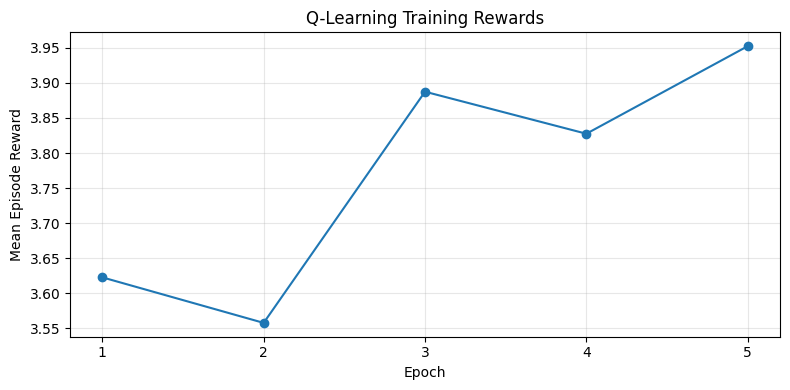

In [40]:
#Visualize Q-learning training progress

plt.figure(figsize=(8, 4))
plt.plot(
    training_history["epoch"],
    training_history["mean_episode_reward"],
    marker="o"
)
plt.title("Q-Learning Training Rewards")
plt.xlabel("Epoch")
plt.ylabel("Mean Episode Reward")
plt.xticks(training_history["epoch"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [41]:
# Display a sample of learned Q-values

display(q_table.round(3))

print("Highest Q-value:", q_table.max().max())
print("Lowest Q-value:", q_table.min().min())

# Show the best-scoring genre for each state
best_genres = q_table.idxmax(axis=1)

best_actions = pd.DataFrame({
    "preferred_genre": q_table.index.get_level_values("preferred_genre"),
    "satisfaction": q_table.index.get_level_values("satisfaction"),
    "best_genre_action": best_genres.values,
    "best_q_value": q_table.max(axis=1).values
})

display(best_actions.head(15))


Action  Adventure  Animation  Children's  \
preferred_genre satisfaction                                             
Action          Low            0.000      0.000      0.000       0.000   
                Medium         0.000      0.000      0.000       0.000   
                High           2.937      1.980      1.848       1.780   
Adventure       Low            0.000      0.000      0.000       0.000   
                Medium         0.363      0.555      0.038       0.090   
                High           2.229      1.998      0.753       1.319   
Animation       Low            0.000      0.000      0.000       0.000   
                Medium         1.650      0.989      3.041       1.487   
                High           2.945      2.806      3.063       2.822   
Children's      Low            0.000      0.000      0.000       0.000   
                Medium         0.658      0.101      0.038       0.499   
                High           2.903      2.726      1.772       2.091   
Comedy          Low            0.000      0.000      0.000       0.000   
                Medium        -0.045      0.099      0.023       0.014   
                High           0.000      0.000      0.000       0.000   
Crime           Low            0.000      0.000      0.000       0.000   
                Medium         0.425      0.165      0.181       0.018   
                High           4.114      2.911      3.575       2.443   
Documentary     Low            0.000      0.000      0.000       0.000   
                Medium         0.170     -0.026      0.393       0.431   
                High           1.281      2.049      1.601       0.773   
Drama           Low            0.000      0.000      0.000       0.000   
                Medium         0.369      0.501      1.070      -0.019   
                High           2.835      2.765      0.547       1.417   
Fantasy         Low            0.000      0.000      0.000       0.000   
                Medium         0.352      0.427     -0.130      -0.247   
                High           2.327      2.238      1.861       1.576   
Film-Noir       Low            0.000     -0.099      0.017      -0.114   
                Medium         2.106      1.150      1.485       0.557   
                High           4.067      4.282      4.593       3.938   
Horror          Low            0.000      0.000      0.000       0.000   
                Medium        -0.046     -0.158      0.000      -0.292   
                High           1.998      1.339      0.567       0.515   
Musical         Low            0.000      0.000      0.000       0.000   
                Medium         0.255      0.224      0.102       0.404   
                High           2.815      1.914      3.235       3.033   
Mystery         Low            0.000      0.000      0.000       0.000   
                Medium         0.765      0.380     -0.041       0.270   
                High           2.091      2.153      2.216       2.136   
Romance         Low            0.000      0.000      0.000       0.000   
                Medium         0.828      0.279      0.228       0.174   
                High           1.258      1.181      0.846       0.739   
Sci-Fi          Low            0.000      0.000      0.000       0.000   
                Medium         0.040      0.063      0.085       0.082   
                High           0.531      0.364      0.404       0.600   
Thriller        Low            0.000      0.000      0.000       0.000   
                Medium         0.000      0.000      0.000       0.000   
                High           0.084      0.418      0.410       0.329   
War             Low            0.000      0.000      0.000       0.000   
                Medium         1.381      1.026      1.695       1.682   
                High           3.701      4.302      3.589       2.770   
Western         Low            0.000      0.000      0.000       0.000   
                Medium         0.0

Highest Q-value: 5.599287592543306
Lowest Q-value: -0.41847600606225493


,preferred_genre,satisfaction,best_genre_action,best_q_value
0,Action,Low,Action,0.000000
1,Action,Medium,Action,0.000000
2,Action,High,Thriller,4.031826
3,Adventure,Low,Action,0.000000
4,Adventure,Medium,Sci-Fi,0.862209
5,Adventure,High,Drama,2.589215
6,Animation,Low,Action,0.000000
7,Animation,Medium,Animation,3.040534
8,Animation,High,Drama,4.117219
9,Children's,Low,Action,0.000000


#### Preparing evaluation data

In [42]:
K = 10

# A test movie is relevant when its rating is 4 or 5
relevant_test = test_ratings[
    test_ratings["rating"].isin([4, 5])
].copy()

# Movies each user has already rated during training
seen_movies = (
    train_ratings.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Relevant test movies that were not seen during training
relevant_test = relevant_test[
    relevant_test.apply(
        lambda row: row["movie_id"] not in seen_movies.get(
            row["user_id"], set()
        ),
        axis=1
    )
].copy()

# Relevant movies grouped by user
relevant_by_user = (
    relevant_test.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Evaluate users who have at least one relevant held-out movie
evaluation_users = sorted(relevant_by_user.keys())

# Calculate popularity from training ratings only
movie_popularity = (
    train_ratings.groupby("movie_id")
    .agg(
        rating_count=("rating", "size"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

# Sort by rating count, then average rating
movie_popularity = movie_popularity.sort_values(
    ["rating_count", "average_rating"],
    ascending=False
).reset_index(drop=True)

print("Relevant test ratings:", len(relevant_test))
print("Evaluation users:", len(evaluation_users))
print("Popular movies available:", len(movie_popularity))
print("K:", K)


Relevant test ratings: 106049
Evaluation users: 5975
Popular movies available: 3667
K: 10


In [43]:
#Prepare movie genres and recommendation helpers

# Map each movie to its genres
movie_genre_map = dict(zip(movies["movie_id"], movies["genre_list"]))

# Global movie popularity order, computed from training data only
popularity_order = movie_popularity["movie_id"].tolist()

# Rating count lookup for popularity ranking
popularity_counts = movie_popularity.set_index(
    "movie_id"
)["rating_count"].to_dict()

# Average rating lookup for popularity tie-breaking
popularity_averages = movie_popularity.set_index(
    "movie_id"
)["average_rating"].to_dict()


def get_q_learning_recommendations(user_id, k=10):
    """Recommend unseen movies using the learned genre Q-values."""

    user_state = user_states.loc[user_id]
    state = (
        user_state["preferred_genre"],
        user_state["satisfaction"]
    )

    # Rank genres by their Q-values for this state
    genre_scores = q_table.loc[state].sort_values(
        ascending=False
    )

    seen = seen_movies.get(user_id, set())
    recommendations = []

    # Follow the learned genre ranking
    for genre in genre_scores.index:
        candidates = [
            movie_id
            for movie_id in popularity_order
            if movie_id not in seen
            and movie_id not in recommendations
            and genre in movie_genre_map.get(movie_id, [])
        ]

        for movie_id in candidates:
            recommendations.append(movie_id)
            if len(recommendations) == k:
                return recommendations

    return recommendations


def get_popularity_recommendations(user_id, k=10):
    """Recommend the most popular unseen movies."""

    seen = seen_movies.get(user_id, set())

    recommendations = [
        movie_id
        for movie_id in popularity_order
        if movie_id not in seen
    ]

    return recommendations[:k]


# Test both methods on one evaluation user
test_user = evaluation_users[0]

print("Test user:", test_user)
print(
    "Q-learning recommendations:",
    get_q_learning_recommendations(test_user, K)
)
print(
    "Popularity recommendations:",
    get_popularity_recommendations(test_user, K)
)


Test user: 1
Q-learning recommendations: [1196, 1210, 110, 356, 1200, 912, 780, 750, 1222, 1094]
Popularity recommendations: [2858, 1196, 1210, 589, 480, 2571, 593, 1198, 1580, 110]


In [44]:
#Evaluate recommendation quality

def calculate_metrics(recommendations_by_user, relevant_by_user, users, k=10):
    hits = []
    precisions = []
    recalls = []
    recommended_catalog = set()

    for user_id in users:
        recommended = recommendations_by_user[user_id][:k]
        relevant = relevant_by_user[user_id]

        # Ensure recommendations are unique
        recommended = list(dict.fromkeys(recommended))

        hit_count = len(set(recommended) & relevant)

        hits.append(1 if hit_count > 0 else 0)
        precisions.append(hit_count / k)
        recalls.append(hit_count / len(relevant))
        recommended_catalog.update(recommended)

    catalog_size = movies["movie_id"].nunique()

    return {
        f"Hit Rate@{k}": np.mean(hits),
        f"Precision@{k}": np.mean(precisions),
        f"Recall@{k}": np.mean(recalls),
        "Catalog Coverage": len(recommended_catalog) / catalog_size
    }


# Generate recommendations for every evaluation user
q_recommendations = {}
pop_recommendations = {}

for i, user_id in enumerate(evaluation_users, start=1):
    q_recommendations[user_id] = get_q_learning_recommendations(
        user_id, K
    )
    pop_recommendations[user_id] = get_popularity_recommendations(
        user_id, K
    )

    if i % 1000 == 0:
        print(f"Processed {i}/{len(evaluation_users)} users")

# Calculate metrics
q_metrics = calculate_metrics(
    q_recommendations, relevant_by_user, evaluation_users, K
)

pop_metrics = calculate_metrics(
    pop_recommendations, relevant_by_user, evaluation_users, K
)

comparison = pd.DataFrame({
    "Q-learning": q_metrics,
    "Popularity baseline": pop_metrics
})

print("\nEvaluation results:")
display(comparison.round(4))


Processed 1000/5975 users
Processed 2000/5975 users
Processed 3000/5975 users
Processed 4000/5975 users
Processed 5000/5975 users

Evaluation results:


,Q-learning,Popularity baseline
Hit Rate@10,0.3006,0.3948
Precision@10,0.0527,0.0810
Recall@10,0.0330,0.0477
Catalog Coverage,0.1028,0.0301


In [45]:
#Saving evaluation results

# Save metric comparison
comparison.to_csv(
    PROCESSED_DIR / "q_learning_evaluation_comparison.csv"
)

# Save recommendation lists for reproducibility and inspection
recommendation_rows = []

for user_id in evaluation_users:
    for method, recommendations in [
        ("Q-learning", q_recommendations[user_id]),
        ("Popularity", pop_recommendations[user_id])
    ]:
        for rank, movie_id in enumerate(recommendations, start=1):
            recommendation_rows.append({
                "user_id": user_id,
                "method": method,
                "rank": rank,
                "movie_id": movie_id,
                "is_relevant": int(
                    movie_id in relevant_by_user[user_id]
                )
            })

recommendation_results = pd.DataFrame(recommendation_rows)

recommendation_results.to_csv(
    PROCESSED_DIR / "q_learning_recommendations.csv",
    index=False
)

print("Saved evaluation files:")
print(PROCESSED_DIR / "q_learning_evaluation_comparison.csv")
print(PROCESSED_DIR / "q_learning_recommendations.csv")

print("\nRecommendation rows:", len(recommendation_results))
print("Unique evaluation users:", recommendation_results["user_id"].nunique())


Saved evaluation files:
C:\Users\Utsab\Desktop\CineRL\data\processed\q_learning_evaluation_comparison.csv
C:\Users\Utsab\Desktop\CineRL\data\processed\q_learning_recommendations.csv

Recommendation rows: 119500
Unique evaluation users: 5975


#### Exploration vs Exploitation Experiment

In [46]:
# Use the same users and training settings for every strategy
experiment_users = sorted(user_interactions.keys())[:200]

experiment_settings = {
    "A_High_Exploration": {
        "initial_epsilon": 1.0,
        "epsilon_decay": 0.90
    },
    "B_Moderate_Exploration": {
        "initial_epsilon": 0.5,
        "epsilon_decay": 0.90
    },
    "C_Slower_Decay": {
        "initial_epsilon": 1.0,
        "epsilon_decay": 0.98
    }
}

experiment_epochs = 5
experiment_max_steps = 10
experiment_learning_rate = 0.1
experiment_discount_factor = 0.9
experiment_epsilon_min = 0.05

experiment_results = []
experiment_q_tables = {}

for strategy_name, settings in experiment_settings.items():

    print(f"\nRunning strategy: {strategy_name}")

    # Reset random seeds for a reproducible comparison
    random.seed(SEED)
    np.random.seed(SEED)

    # Each strategy gets its own fresh Q-table
    experiment_q = q_table.copy()
    experiment_q.loc[:, :] = 0.0

    epsilon = settings["initial_epsilon"]

    for epoch in range(1, experiment_epochs + 1):
        start_time = time.perf_counter()
        epoch_rewards = []

        for user_id in experiment_users:
            state = env.reset(user_id)
            episode_reward = 0.0

            for _ in range(experiment_max_steps):
                available = env.available_actions()

                if not available:
                    break

                action = choose_action(
                    state=state,
                    q_table=experiment_q,
                    epsilon=epsilon,
                    available_actions=available
                )

                next_state, reward, done, info = env.step(action)

                update_q_value(
                    q_table=experiment_q,
                    state=state,
                    action=action,
                    reward=reward,
                    next_state=next_state,
                    learning_rate=experiment_learning_rate,
                    discount_factor=experiment_discount_factor
                )

                episode_reward += reward
                state = next_state

                if done:
                    break

            epoch_rewards.append(episode_reward)

        elapsed = time.perf_counter() - start_time
        mean_reward = float(np.mean(epoch_rewards))

        experiment_results.append({
            "strategy": strategy_name,
            "epoch": epoch,
            "mean_episode_reward": mean_reward,
            "epsilon": epsilon,
            "runtime_seconds": elapsed
        })

        print(
            f"Epoch {epoch}/{experiment_epochs} | "
            f"Mean reward: {mean_reward:.3f} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Time: {elapsed:.2f}s"
        )

        epsilon = max(
            experiment_epsilon_min,
            epsilon * settings["epsilon_decay"]
        )

    # Preserve this strategy's learned Q-table in memory
    experiment_q_tables[strategy_name] = experiment_q.copy()

experiment_history = pd.DataFrame(experiment_results)

print("\nAll exploration experiments completed.")
display(experiment_history)


Running strategy: A_High_Exploration
Epoch 1/5 | Mean reward: 3.623 | Epsilon: 1.000 | Time: 2.09s
Epoch 2/5 | Mean reward: 3.558 | Epsilon: 0.900 | Time: 2.52s
Epoch 3/5 | Mean reward: 3.888 | Epsilon: 0.810 | Time: 3.07s
Epoch 4/5 | Mean reward: 3.828 | Epsilon: 0.729 | Time: 3.49s
Epoch 5/5 | Mean reward: 3.953 | Epsilon: 0.656 | Time: 3.57s

Running strategy: B_Moderate_Exploration
Epoch 1/5 | Mean reward: 3.732 | Epsilon: 0.500 | Time: 4.09s
Epoch 2/5 | Mean reward: 4.082 | Epsilon: 0.450 | Time: 4.17s
Epoch 3/5 | Mean reward: 4.390 | Epsilon: 0.405 | Time: 4.44s
Epoch 4/5 | Mean reward: 4.310 | Epsilon: 0.365 | Time: 4.53s
Epoch 5/5 | Mean reward: 4.228 | Epsilon: 0.328 | Time: 4.72s

Running strategy: C_Slower_Decay
Epoch 1/5 | Mean reward: 3.623 | Epsilon: 1.000 | Time: 2.33s
Epoch 2/5 | Mean reward: 3.660 | Epsilon: 0.980 | Time: 2.45s
Epoch 3/5 | Mean reward: 3.835 | Epsilon: 0.960 | Time: 2.43s
Epoch 4/5 | Mean reward: 3.902 | Epsilon: 0.941 | Time: 2.46s
Epoch 5/5 | Mean r

,strategy,epoch,mean_episode_reward,epsilon,runtime_seconds
0,A_High_Exploration,1,3.6225,1.000000,2.091799
1,A_High_Exploration,2,3.5575,0.900000,2.523248
2,A_High_Exploration,3,3.8875,0.810000,3.068496
3,A_High_Exploration,4,3.8275,0.729000,3.493492
4,A_High_Exploration,5,3.9525,0.656100,3.568183
5,B_Moderate_Exploration,1,3.7325,0.500000,4.092018
6,B_Moderate_Exploration,2,4.0825,0.450000,4.174293
7,B_Moderate_Exploration,3,4.3900,0.405000,4.439214
8,B_Moderate_Exploration,4,4.3100,0.364500,4.527535
9,B_Moderate_Exploration,5,4.2275,0.328050,4.719597


In [47]:
# Save exploration experiment results

# Save the complete experiment history
experiment_history.to_csv(
    PROCESSED_DIR / "exploration_experiment_results.csv",
    index=False
)

# Save each strategy's Q-table separately
for strategy_name, strategy_q_table in experiment_q_tables.items():
    filename = f"q_table_{strategy_name.lower()}.csv"
    strategy_q_table.to_csv(PROCESSED_DIR / filename)

# Summarize performance by strategy
strategy_summary = (
    experiment_history.groupby("strategy")
    .agg(
        mean_reward=("mean_episode_reward", "mean"),
        best_reward=("mean_episode_reward", "max"),
        total_runtime=("runtime_seconds", "sum")
    )
    .round(4)
)

print("Saved exploration experiment results.")
print("\nStrategy summary:")
display(strategy_summary)

print("\nFiles saved in:", PROCESSED_DIR)


Saved exploration experiment results.

Strategy summary:


,mean_reward,best_reward,total_runtime
strategy,,,
A_High_Exploration,3.7695,3.9525,14.7452
B_Moderate_Exploration,4.1485,4.3900,21.9527
C_Slower_Decay,3.7160,3.9025,12.3238



Files saved in: C:\Users\Utsab\Desktop\CineRL\data\processed
